## Environmental Performance Model

# T3.3 EIT-001 Environmental Monitoring Tool

READ.ME

This notebook calls the databases and project defined in EIT-003 and handles the import and integration of sensor data into the LCIs.

- Setting the project 
- Relevant sensor data manipulation 
- Integration in foreground database as scenario
- LCA results in DPP format

> The functionalities represent the requirements for EU REED WP3 T3.3 EIT-001 deliverable. Notebook depends on 1) EIT-003 Environmental Performance Model

### 1. Set the project and databases imported in EIT-003

In [97]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config
import bw_processing as bwp
from bw2io.strategies.generic import set_code_by_activity_hash


import matplotlib.pyplot as plt
import d3graph
import polyviz

import json
from datetime import date

In [98]:
config = Config()

In [99]:
bd.projects.set_current(config.PROJECT_NAME)

In [100]:
bd.databases

Databases dictionary with 4 object(s):
	BONSAI_V2.1.6
	BONSAI_V2.1.6 biosphere
	ecoinvent-3.10-biosphere
	reed

In [101]:
bonsai = bd.Database('BONSAI_V2.1.6')
bonsai_bio = bd.Database('BONSAI_V2.1.6 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')
reed = bd.Database('reed')

### 2. Import sensor data

This part draws from defined functions in the script, sensordata_analysis.py. It imports the monitoring data and calculates the energy consumption per tool and connect the tools to the reed tools

In [102]:
from reed.sensordata_analysis import (
    run_sensordata_analysis,
    find_missing_op_type_tools,
    compute_event_totals,
    split_final_df_by_company_event,
    sum_by_reed_tool,
    split_final_df_by_company_event,
)

In [103]:
monitoring_data_path = config.REED_PATH/'Data'/"MonitoringData"/"Data"
tool_descriptions_path = config.REED_PATH/'Data'/"MonitoringData"

In [104]:
sensordata, event_summaries_df, ambiguous_company_tools, key_company_tools, key_reed_tools = run_sensordata_analysis(
    monitoring_data_path,
    tool_descriptions_path,
)
print(sensordata)

C:\Users\TimWeber\repos_20LCA\REED\reed\src\reed\sensordata_analysis.py:132: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f)


                                                  energy_consumption  \
company event_id                     Tool_Number                       
goimek  OF10001_G_BQC_S8CF2G         0.0                    8.154403   
                                     1.0                   24.300319   
                                     2.0                   10.289347   
                                     3.0                   14.673875   
                                     4.0                    0.930889   
...                                                              ...   
wwr     OF10005_SETUPS2_G_TWB_7SZ421 2694.0                 2.915730   
                                     2695.0                 1.068689   
                                     2696.0                 2.709187   
                                     2722.0                 0.631658   
                                     3350.0                23.502143   

                                                  Power_Active 

Identify tools that have different operation type in the key_company_tools. These tool numbers are removed from the key to avoid an ambigious key. These tool numbers will be assigned to the generic machining process in the reed database

In [105]:
print(ambiguous_company_tools)

   company  Tool_Number                   op_type_candidates
0   goimek            2                 [AUXILIARY, MILLING]
1   goimek            6                 [AUXILIARY, MILLING]
2   goimek           30                 [AUXILIARY, MILLING]
3   goimek           31                   [CHAMFER, MILLING]
4   goimek           44                 [AUXILIARY, MILLING]
5   goimek           45                 [AUXILIARY, MILLING]
6  komatsu            3           [AUXILIARY, ROUGH MILLING]
7  komatsu           48  [AUXILIARY, MILLING, ROUGH MILLING]
8  komatsu           50        [ROUGH BORING, ROUGH MILLING]
9  komatsu           72      [FINISH MILLING, ROUGH MILLING]


In [106]:
#Identify missing op type tools, e.g. tools that are in the monitoring data but not in tool descriptions
missing_tool_descriptions = find_missing_op_type_tools(sensordata)

In [107]:
#Compute total time and energy per event per company
event_totals = compute_event_totals(sensordata, event_summaries_df)

### 3. Scenario setup for sensor data integation

this section is missing a part about how to handle the processes that are not in hours?

In [108]:
from reed.swapping_data import (
    find_activities_by_name,
    build_scenarios_from_power_active,
    build_consumer_input_scenarios_from_hours,
    describe_scenarios,
    lcia_for_activity_with_scenario,
    find_subactivity_by_name_fragment,
    build_consumer_input_scenarios_from_hours_for_activity,
    get_product_id_for_activity,
)

Select which event you want to analyse

In [109]:
company = "goimek"
event_id = "OF10005_G_BQC_S8CF2G"
product = "GOIMEK total"
demand = 1

Start by selected the company and event_id where you want to swap in the sensordata

In [110]:
#Split sensordata by company and event
event_dfs = split_final_df_by_company_event(sensordata)

#Compute energy by reed tool for a specific company and event
tool_energy_by_company_and_event = sum_by_reed_tool(
    event_dfs[(company, event_id)]
)
print(tool_energy_by_company_and_event)

                                                          energy_consumption  \
company event_id             reed tool                                         
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce                    28.517208   
                             generic machining, soraluce          115.554208   
                             milling, soraluce                     35.696639   

                                                              hours  \
company event_id             reed tool                                
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce           50.165556   
                             generic machining, soraluce   9.222778   
                             milling, soraluce             3.079722   

                                                          Power_Active  
company event_id             reed tool                                  
goimek  OF10005_G_BQC_S8CF2G drilling, soraluce               0.568462  
                        


Find all processes present in the sensordata in the reed-database

In [111]:
tools = tool_energy_by_company_and_event.index.get_level_values("reed tool").unique()
found = {t: find_activities_by_name(reed, t, exact=False) for t in tools}
found

{'drilling, soraluce': ['drilling, soraluce' (kilogram, DE, None),
  'drilling, soraluce' (hour, ES, None),
  'drilling, soraluce' (hour, GB, None),
  'drilling, soraluce' (kilogram, ES, None),
  'drilling, soraluce' (hour, DE, None),
  'drilling, soraluce' (kilogram, GB, None)],
 'generic machining, soraluce': ['generic machining, soraluce' (kilogram, GB, None),
  'generic machining, soraluce' (hour, GB, None),
  'generic machining, soraluce' (hour, DE, None),
  'generic machining, soraluce' (kilogram, ES, None),
  'generic machining, soraluce' (kilogram, DE, None),
  'generic machining, soraluce' (hour, ES, None)],
 'milling, soraluce': ['milling, soraluce' (hour, DE, None),
  'milling, soraluce' (kilogram, ES, None),
  'milling, soraluce' (kilogram, DE, None),
  'milling, soraluce' (hour, ES, None),
  'milling, soraluce' (hour, GB, None),
  'milling, soraluce' (kilogram, GB, None)]}

Find subactivities called A3 for the product under study

In [112]:
product_activity = reed.get(name=product)

# Find the A3 activity inside KOMATSU total
a3_matches = find_subactivity_by_name_fragment(
    parent_activity=product_activity,
    name_fragment="A3",
)

print(a3_matches)
a3_activity = a3_matches[0]

['GOIMEK A3: machining' (unit, ES, None)]


In [113]:
soraluce_matches = find_subactivity_by_name_fragment(
    parent_activity=a3_activity,
    name_fragment="soraluce machining",
)

print(soraluce_matches)

soraluce_activity = soraluce_matches[0]

['Soraluce machining, GOIMEK' (unit, ES, None)]


In [114]:
#Identifying the electricity activity in bonsai to be able to compute the original electricity input amount for the activities found above
electricity = bonsai.get(name='production of electricity (market for)', location='GB', unit='TJ')

Create scenario where alle electricity inputs from the sensordata to the processes identified in found.

In [115]:
scenarios = build_scenarios_from_power_active(tool_energy_by_company_and_event, found, electricity)
scenarios


original  goimek_OF10005_G_BQC_S8CF2G
product            activity                                                 
310325776270831700 310338392082952193  0.000000                     0.000002
                   310338391978094592  0.000015                     0.000045
                   310338392045203456  0.000000                     0.000042

The input of products in found to consuming activities are found and used to build scenarios.

In [116]:
consumer_scenarios = build_consumer_input_scenarios_from_hours_for_activity(
    tool_energy_by_company_and_event,
    found,
    consumer_activity=soraluce_activity,
)
consumer_scenarios

,,original,goimek_OF10005_G_BQC_S8CF2G
product,activity,,
310338392007454720,310338392175226880,0.000000,9.222778
310338392061980672,310338392175226880,29.705051,3.079722


In [117]:
full_scenario = pd.concat([scenarios, consumer_scenarios])

In [118]:
full_scenario_readable = describe_scenarios(full_scenario)
full_scenario_readable

,product_name,product_unit,activity_name,activity_unit,original,goimek_OF10005_G_BQC_S8CF2G
0,production of electricity (market for),TJ,"drilling, soraluce",hour,0.000000,0.000002
1,production of electricity (market for),TJ,"generic machining, soraluce",hour,0.000015,0.000045
2,production of electricity (market for),TJ,"milling, soraluce",hour,0.000000,0.000042
3,"generic machining, soraluce",hour,"Soraluce machining, GOIMEK",unit,0.000000,9.222778
4,"milling, soraluce",hour,"Soraluce machining, GOIMEK",unit,29.705051,3.079722


#### 3.1. Initial LCA scores for Monitoring Footprint

LCA score with sensor data

In [119]:
score, lca = lcia_for_activity_with_scenario(
    activity=product_activity,
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    scenario_col=None,     # "original" or None (for defined scenario)
    amount=demand
)
score


15667.524557200273

LCA score without sensor data

In [120]:
product_reed = product_activity
lca = product_reed.lca(method=config.lcia_gwp100)
lca.score

15892.94268114718

In [121]:
goimek_total = reed.get(name="GOIMEK total", location="ES", unit="unit")

In [122]:
bwa.print_recursive_calculation(goimek_total,
lcia_method=config.lcia_gwp100,max_level=1,cutoff=0.001)

Fraction of score | Absolute score | Amount | Activity
0001 | 1.589e+04 |     1 | 'GOIMEK total' (unit, ES, None)
  1.06 | 1.682e+04 |     1 | 'GOIMEK A1: material input' (unit, ES, None)
  0.0143 | 227.7 |     1 | 'GOIMEK A2: transport' (unit, ES, None)
  0.0261 | 414.8 |     1 | 'GOIMEK A3: machining' (unit, ES, None)
  -0.0987 | -1,569 |   0.8 | 'treatment of steel, industrial waste (market for)' (ton, ES, None)


### 4. Digital Product Passport

#### 4.1 Functions for DPP alignment

In [123]:
def lcia_score_for_named_input(
    parent_activity,
    name_fragment,
    method,
    scenario_df=None,
    scenario_col=None,
    amount=1.0,
):
    """
    Calculate LCIA score for direct inputs of parent_activity whose names contain name_fragment.
    Applies scenario_df if provided.
    """
    matches = [
        exc for exc in parent_activity.technosphere()
        if name_fragment.lower() in exc.input.get("name", "").lower()
    ]

    if not matches:
        raise ValueError(
            f"No input containing '{name_fragment}' found in {parent_activity.get('name')}"
        )

    total_score = 0

    for exc in matches:
        input_activity = exc.input
        input_amount = float(exc["amount"]) * amount

        if scenario_df is None:
            fu, data_objs, _ = bd.prepare_lca_inputs(
                {input_activity: input_amount},
                method=method,
            )

            lca = bc.LCA(fu, method=method, data_objs=data_objs)
            lca.lci()
            lca.lcia()

            total_score += lca.score

        else:
            score, _ = lcia_for_activity_with_scenario(
                activity=input_activity,
                method=method,
                scenario_df=scenario_df,
                scenario_col=scenario_col,
                amount=input_amount,
            )

            total_score += score

    return total_score

In [124]:
score_A1 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A1",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

score_A2 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A2",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

score_A3 = lcia_score_for_named_input(
    parent_activity=product_activity,
    name_fragment="A3",
    method=config.lcia_gwp100,
    scenario_df=full_scenario,
    amount=demand,
)

In [125]:
score_total = score_A1 + score_A2 + score_A3
score_total

17236.669761041172

#### 4.2 To be shared with TUDa

In [157]:
activity = reed.get(name=product)
location = activity.get("location")
unit = activity.get("unit")

def make_pcf_entry(score, life_cycle_phase):
    return {
        "PcfCalculationMethods": [
            {
                "PcfCalculationMethod": "ISO 14044"
            }
        ],
        "PCF in kg CO2eq": round(score, 1),
        "ProcessName": f"{product} {life_cycle_phase}",
        "ReferenceValueForCalculation": unit,
        "QuantityOfMeasureForCalculation": demand,
        "LifeCyclePhases": [
            {
                "LifeCyclePhase": life_cycle_phase
            }
        ],
        "ExplanatoryStatement": (
            "Product Carbon Footprint associated with the cradle-to-gate life cycle phases (A1-A3) of the product, calculated using the specific production data provided by the company for this product."
        ),
        "GoodsHandoverAddress": {
            "Country": location
        },
        "PublicationDate": date.today().isoformat(),
        # "ExpirationDate": "2027-03-06"
    }

dpp_output = {
    "DPP": [
        {
            "company": company,
            "event_id": event_id,
            "product": product,
            "carbonFootprint": {
                "ProductCarbonFootprints": [
                    make_pcf_entry(score_A1, "A1"),
                    make_pcf_entry(score_A2, "A2"),
                    make_pcf_entry(score_A3, "A3"),
                    make_pcf_entry(score_A1 + score_A2 + score_A3, "A1-A3")  # optional total
                ]
            }
        }
    ]
}

dpp_output


{'DPP': [{'company': 'goimek',
   'event_id': 'OF10005_G_BQC_S8CF2G',
   'product': 'GOIMEK total',
   'carbonFootprint': {'ProductCarbonFootprints': [{'PcfCalculationMethods': [{'PcfCalculationMethod': 'ISO 14044'}],
      'PCF in kg CO2eq': 16819.5,
      'ProcessName': 'GOIMEK total A1',
      'ReferenceValueForCalculation': 'unit',
      'QuantityOfMeasureForCalculation': 1,
      'LifeCyclePhases': [{'LifeCyclePhase': 'A1'}],
      'ExplanatoryStatement': 'Product Carbon Footprint associated with the cradle-to-gate life cycle phases (A1-A3) of the product, calculated using the specific production data provided by the company for this product.',
      'GoodsHandoverAddress': {'Country': 'ES'},
      'PublicationDate': '2026-05-06'},
     {'PcfCalculationMethods': [{'PcfCalculationMethod': 'ISO 14044'}],
      'PCF in kg CO2eq': 227.7,
      'ProcessName': 'GOIMEK total A2',
      'ReferenceValueForCalculation': 'unit',
      'QuantityOfMeasureForCalculation': 1,
      'LifeCyclePha

In [158]:
# Export to JSON file
filename = f"DPP_{company}_{event_id}_{date.today().isoformat()}.json"

with open(filename, "w") as f:
    json.dump(dpp_output, f, indent=2)

print(f"Exported to {filename}")

Exported to DPP_goimek_OF10005_G_BQC_S8CF2G_2026-05-06.json


# Supplementary Material

#### 5. Defining Life Cycle Stages for Use Cases

In [128]:
reed.search('goimek')

['Soraluce machining, GOIMEK' (unit, ES, None),
 'GOIMEK A3: machining' (unit, ES, None),
 'GOIMEK A2: transport' (unit, ES, None),
 'soraluce machine, Goimek' (unit, ES, None),
 'GOIMEK A1: material input' (unit, ES, None),
 'GOIMEK total' (unit, ES, None)]

In [129]:
komatsu_processes = {
    "KOMATSU total": reed.get(name='KOMATSU total', location="GB", unit='unit'),
    "KOMATSU A1: raw materials": reed.get(name='KOMATSU A1: raw materials', location="GB", unit='unit'),
    "KOMATSU A2: transport": reed.get(name='KOMATSU A2: transport', location="GB", unit='unit'),
    "KOMATSU A3: machining": reed.get(name='KOMATSU A3: machining', location="GB", unit='unit'),
    
}

In [130]:
wwr_processes = {
    "WWR total": reed.get(name='WWR total', location="DE", unit='unit'),
    "WWR A1: material inputs": reed.get(name='WWR A1: material inputs', location="DE", unit='unit'),
    "WWR A2: transport": reed.get(name='WWR A2: transport', location="DE", unit='unit'),
    "WWR A3: machining": reed.get(name='WWR A3: machining', location="DE", unit='unit'),
}

In [131]:
goimek_processes = {
    "GOIMEK total": reed.get(name='GOIMEK total', location="ES", unit='unit'),
    "GOIMEK A1: material input": reed.get(name='GOIMEK A1: material input', location="ES", unit='unit'),
    "GOIMEK A2: transport": reed.get(name='GOIMEK A2: transport', location="ES", unit='unit'),
    "GOIMEK A3: machining": reed.get(name='GOIMEK A3: machining', location="ES", unit='unit'),
}

#### 6. LCA scores for Life Cycle Stages

In [132]:
from reed.LCA_functions import (
    lca_score,
    run_contribution_analysis,
    plot_contribution
)

In [133]:
df_komatsu_results = lca_score(komatsu_processes, config.lcia_gwp100)
display(df_komatsu_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11218.720720
1,KOMATSU A1: raw materials,GB,unit,10528.619943
2,KOMATSU A2: transport,GB,unit,200.358879
3,KOMATSU A3: machining,GB,unit,837.769047


In [134]:
df_wwr_results = lca_score(wwr_processes, config.lcia_gwp100)
display(df_wwr_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,WWR total,DE,unit,39553.273397
1,WWR A1: material inputs,DE,unit,39402.083656
2,WWR A2: transport,DE,unit,518.927112
3,WWR A3: machining,DE,unit,900.987143


In [135]:
df_goimek_results = lca_score(goimek_processes, config.lcia_gwp100)
display(df_goimek_results)


,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,GOIMEK total,ES,unit,15892.942681
1,GOIMEK A1: material input,ES,unit,16819.521795
2,GOIMEK A2: transport,ES,unit,227.748308
3,GOIMEK A3: machining,ES,unit,414.817783


In [136]:
df_results_all = pd.concat(
    [df_komatsu_results, df_wwr_results, df_goimek_results],
    ignore_index=True
)
df_results_all

,Process,Location,Functional Unit,Climate Impact (kg CO2eq)
0,KOMATSU total,GB,unit,11218.720720
1,KOMATSU A1: raw materials,GB,unit,10528.619943
2,KOMATSU A2: transport,GB,unit,200.358879
3,KOMATSU A3: machining,GB,unit,837.769047
4,WWR total,DE,unit,39553.273397
5,WWR A1: material inputs,DE,unit,39402.083656
6,WWR A2: transport,DE,unit,518.927112
7,WWR A3: machining,DE,unit,900.987143
8,GOIMEK total,ES,unit,15892.942681
9,GOIMEK A1: material input,ES,unit,16819.521795


#### 7. Plot results

In [137]:
import bw2analyzer as bwa

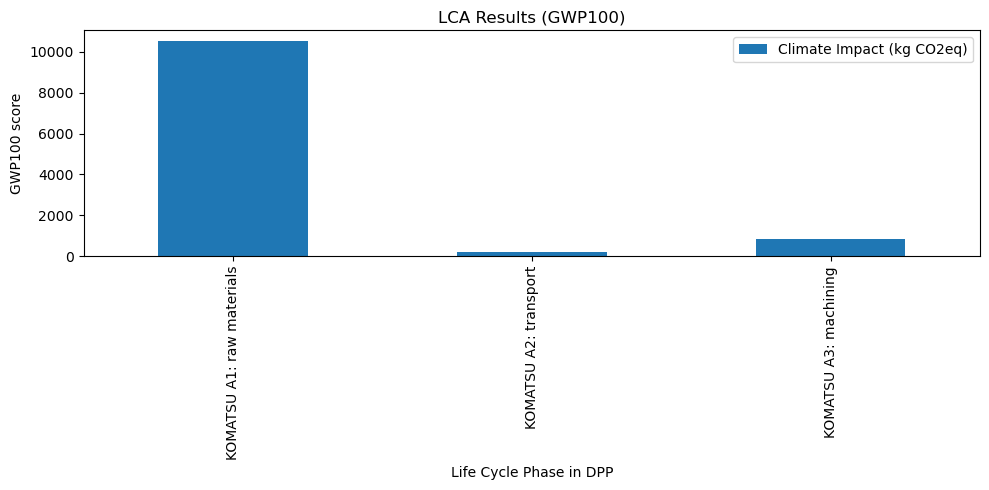

In [138]:
df_plot = df_komatsu_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("KOMATSU total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

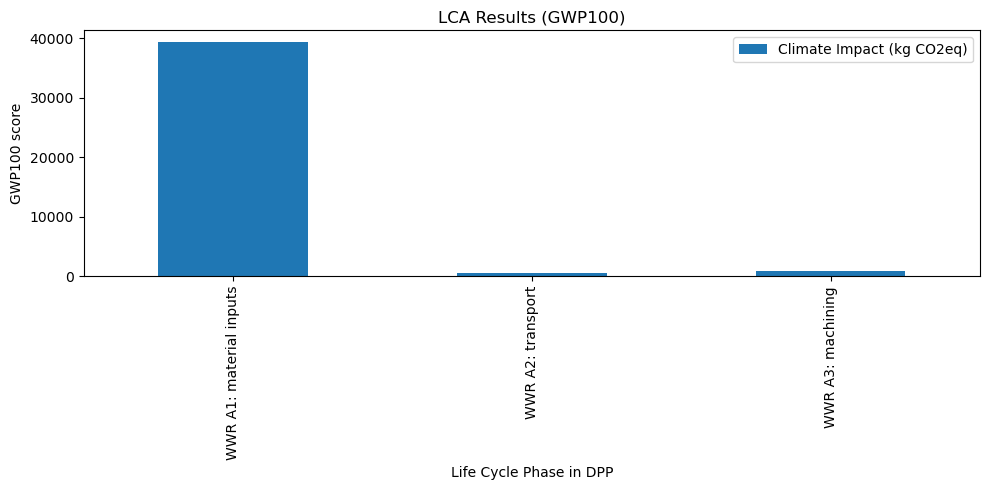

In [139]:
df_plot = df_wwr_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("WWR total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()

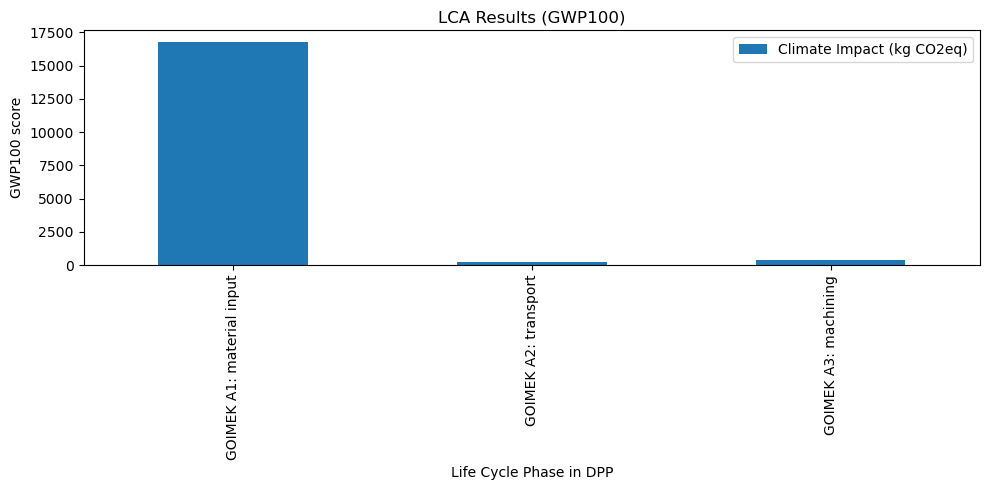

In [140]:
df_plot = df_goimek_results.set_index("Process")

# Remove the row
df_plot = df_plot.drop("GOIMEK total", errors="ignore")

ax = df_plot.plot(kind="bar", figsize=(10, 5))

ax.set_title("LCA Results (GWP100)")
ax.set_xlabel("Life Cycle Phase in DPP")
ax.set_ylabel("GWP100 score")

plt.tight_layout()
plt.show()